# Programa.Normalización y estandarización de datos médicos con CRISP DM
![logo ITQ](img/ITQ.png)


**Nombre:** Emerson Gonzalo Suquillo Cuzco


**Fecha:** 23-11-2026


**link del repositorio:** <a href=" ">Link Repositorio</a> 


**Conocimiento:** Normalizacion, Estandaraizacion, Deteccion de Outlers y limpieza

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo

# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)

# Obtener una copia de todos los datos.
df = dataset.data.original.copy()

# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."

# Visualizar los primeros registros.
display(df.head())

# Consultar el diccionario de variables.
display(dataset.variables)

# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)
 

C:\Users\PC\anaconda3\envs\fundamentosenmachinlearning\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


In [3]:
from datetime import datetime
from importlib.metadata import version
import sys

print("Fecha de descarga:", datetime.now().strftime("%Y-%m-%d"))
print("Dimensiones:", df.shape)
print("Python:", sys.version.split()[0])
print("ucimlrepo:", version("ucimlrepo"))
print("pandas:", version("pandas"))

Fecha de descarga: 2026-11-22
Dimensiones: (101766, 50)
Python: 3.13.18
ucimlrepo: 0.0.7
pandas: 2.3.3


## Fase 1. Comprensión del negocio

### Problema
El equipo hospitalario necesita explorar las características de las hospitalizaciones de personas con diabetes y describir su relación con la readmisión. Antes de construir un modelo, debe conocer la calidad de los datos y preparar variables cuantitativas comparables.

### Actores interesados
El equipo de análisis y el personal responsable de estudiar las readmisiones hospitalarias.

### Objetivo general
Comprender los registros de hospitalización y preparar siete variables cuantitativas mediante normalización Min-Max y estandarización Z-score, conservando versiones independientes de los datos.

### Preguntas de análisis
1. ¿Cómo se distribuyen las siete variables cuantitativas seleccionadas?
2. ¿Qué frecuencias presentan las categorías de la variable `readmitted`?
3. ¿Cómo cambian los valores de esas variables después de normalizarlas y estandarizarlas?

### Criterios de éxito
- Confirmar que se cargaron más de 100 000 hospitalizaciones.
- Documentar la calidad de los datos y justificar las decisiones de limpieza.
- Obtener y comprobar una versión normalizada y otra estandarizada de las siete variables.
- Comparar ambas versiones con los datos originales y exportarlas a archivos CSV.

### Variable de referencia
`readmitted` indica si existe un registro de readmisión: `NO` significa que no se registró una readmisión, `<30` indica readmisión en menos de 30 días y `>30` indica readmisión después de más de 30 días. Esta variable es categórica y no se escalará.

### Límites del análisis
Los registros proceden del periodo 1999–2008 y de hospitales de Estados Unidos. Una fila representa una hospitalización, por lo que varias filas pueden corresponder al mismo paciente. El análisis es académico y descriptivo: no establece causas ni permite emitir diagnósticos. Se mantendrá la confidencialidad y no se intentará identificar personas.

## Fase 2. Comprensión de los datos

### Dimensiones y pacientes
Se verificará el número de filas y columnas del conjunto. Cada fila representa una hospitalización; por eso, el número de hospitalizaciones puede ser mayor que el número de pacientes únicos.

In [4]:
print("Filas y columnas:", df.shape)
print("Número de hospitalizaciones:", len(df))
print("Número de pacientes únicos:", df["patient_nbr"].nunique())

Filas y columnas: (101766, 50)
Número de hospitalizaciones: 101766
Número de pacientes únicos: 71518


### Interpretación de las dimensiones

El conjunto contiene 101 766 filas y 50 columnas. Cada fila representa una hospitalización, mientras que `patient_nbr` identifica al paciente. Se encontraron 71 518 pacientes únicos, por lo que un paciente puede tener más de un registro de hospitalización. La repetición de ese identificador no demuestra por sí sola que las filas sean duplicados.

In [5]:
import pandas as pd

tipos_observados = pd.DataFrame({
    "nombre": df.columns,
    "tipo_observado": df.dtypes.astype(str).values
})

display(tipos_observados)
display(dataset.variables)

,nombre,tipo_observado
0,encounter_id,int64
1,patient_nbr,int64
2,race,object
3,gender,object
4,age,object
5,weight,object
6,admission_type_id,int64
7,discharge_disposition_id,int64
8,admission_source_id,int64
9,time_in_hospital,int64


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


### Tipos de variables

El tipo observado indica cómo Python almacena los datos (`int64` u `object`). El tipo conceptual indica qué representan. Los identificadores y los códigos categóricos no son magnitudes cuantitativas aunque estén escritos como números. `readmitted` es la variable categórica de referencia y no se escalará.

In [6]:
metadatos = dataset.variables.set_index("name").reindex(df.columns)

diccionario = pd.DataFrame({
    "nombre": df.columns,
    "significado": metadatos["description"].values,
    "tipo_observado": df.dtypes.astype(str).values,
    "tipo_conceptual": metadatos["type"].map({
        "Categorical": "Categórica",
        "Integer": "Cuantitativa discreta"
    }).values,
    "unidades_o_categorias": metadatos["units"].values,
    "rol_analitico": metadatos["role"].map({
        "ID": "Identificador",
        "Feature": "Variable de análisis",
        "Target": "Variable de referencia"
    }).values
})

diccionario.loc[
    diccionario["rol_analitico"] == "Identificador",
    "tipo_conceptual"
] = "Identificador"

display(diccionario)

,nombre,significado,tipo_observado,tipo_conceptual,unidades_o_categorias,rol_analitico
0,encounter_id,Unique identifier of an encounter,int64,Identificador,None,Identificador
1,patient_nbr,Unique identifier of a patient,int64,Identificador,None,Identificador
2,race,"Values: Caucasian, Asian, African American, Hi...",object,Categórica,None,Variable de análisis
3,gender,"Values: male, female, and unknown/invalid",object,Categórica,None,Variable de análisis
4,age,"Grouped in 10-year intervals: [0, 10), [10, 20...",object,Categórica,None,Variable de análisis
5,weight,Weight in pounds.,object,Categórica,None,Variable de análisis
6,admission_type_id,Integer identifier corresponding to 9 distinct...,int64,Categórica,None,Variable de análisis
7,discharge_disposition_id,Integer identifier corresponding to 29 distinc...,int64,Categórica,None,Variable de análisis
8,admission_source_id,Integer identifier corresponding to 21 distinc...,int64,Categórica,None,Variable de análisis
9,time_in_hospital,Integer number of days between admission and d...,int64,Cuantitativa discreta,None,Variable de análisis


In [7]:
unidades_o_categorias = []

for nombre in diccionario["nombre"]:
    tipo = diccionario.loc[
        diccionario["nombre"] == nombre, "tipo_conceptual"
    ].iloc[0]

    if tipo == "Identificador":
        detalle = "Identificador"

    elif nombre == "time_in_hospital":
        detalle = "Días"

    elif tipo == "Cuantitativa discreta":
        detalle = "Conteo"

    elif nombre == "weight":
        detalle = "Intervalos de peso en libras"

    else:
        categorias = df[nombre].dropna().astype(str).unique()

        if len(categorias) <= 12:
            detalle = ", ".join(sorted(categorias))
        else:
            detalle = f"{len(categorias)} categorías observadas; consultar descripción"

    unidades_o_categorias.append(detalle)

diccionario["unidades_o_categorias"] = unidades_o_categorias

display(diccionario)

,nombre,significado,tipo_observado,tipo_conceptual,unidades_o_categorias,rol_analitico
0,encounter_id,Unique identifier of an encounter,int64,Identificador,Identificador,Identificador
1,patient_nbr,Unique identifier of a patient,int64,Identificador,Identificador,Identificador
2,race,"Values: Caucasian, Asian, African American, Hi...",object,Categórica,"AfricanAmerican, Asian, Caucasian, Hispanic, O...",Variable de análisis
3,gender,"Values: male, female, and unknown/invalid",object,Categórica,"Female, Male, Unknown/Invalid",Variable de análisis
4,age,"Grouped in 10-year intervals: [0, 10), [10, 20...",object,Categórica,"[0-10), [10-20), [20-30), [30-40), [40-50), [5...",Variable de análisis
5,weight,Weight in pounds.,object,Categórica,Intervalos de peso en libras,Variable de análisis
6,admission_type_id,Integer identifier corresponding to 9 distinct...,int64,Categórica,"1, 2, 3, 4, 5, 6, 7, 8",Variable de análisis
7,discharge_disposition_id,Integer identifier corresponding to 29 distinc...,int64,Categórica,26 categorías observadas; consultar descripción,Variable de análisis
8,admission_source_id,Integer identifier corresponding to 21 distinc...,int64,Categórica,17 categorías observadas; consultar descripción,Variable de análisis
9,time_in_hospital,Integer number of days between admission and d...,int64,Cuantitativa discreta,Días,Variable de análisis


### Valores ausentes por columna

Se cuantifican los valores nulos y los registros marcados con `?` en cada columna. Se calcula su cantidad y porcentaje respecto de las 101 766 hospitalizaciones. Antes de tratar otros valores, como la categoría `None`, se revisará su significado en el diccionario de variables.

In [8]:
nulos = df.isna().sum()
marcadores_interrogacion = df.eq("?").sum()

resumen_faltantes = pd.DataFrame({
    "columna": df.columns,
    "nulos": nulos.values,
    "marcador_?": marcadores_interrogacion.values
})

resumen_faltantes["total_ausentes"] = (
    resumen_faltantes["nulos"] +
    resumen_faltantes["marcador_?"]
)

resumen_faltantes["porcentaje_ausentes"] = (
    resumen_faltantes["total_ausentes"] / len(df) * 100
).round(2)

display(resumen_faltantes)

,columna,nulos,marcador_?,total_ausentes,porcentaje_ausentes
0,encounter_id,0,0,0,0.00
1,patient_nbr,0,0,0,0.00
2,race,2273,0,2273,2.23
3,gender,0,0,0,0.00
4,age,0,0,0,0.00
5,weight,98569,0,98569,96.86
6,admission_type_id,0,0,0,0.00
7,discharge_disposition_id,0,0,0,0.00
8,admission_source_id,0,0,0,0.00
9,time_in_hospital,0,0,0,0.00


### Revisión de valores ausentes

El conjunto contiene 101 766 hospitalizaciones. Se observaron valores ausentes en `race` (2 273; 2,23 %), `weight` (98 569; 96,86 %), `payer_code` (40 256; 39,56 %), `medical_specialty` (49 949; 49,08 %), `diag_1` (21; 0,02 %), `diag_2` (358; 0,35 %) y `diag_3` (1 423; 1,40 %).

La tabla también muestra nulos en `max_glu_serum` y `A1Cresult`. Según el diccionario de UCI, `None` indica que la prueba no se realizó. Por tanto, esos registros representan una categoría válida y no se imputarán como datos ausentes. Esta distinción se tendrá en cuenta durante la limpieza.

No se observaron marcadores `?` en el DataFrame cargado; los faltantes detectados aparecen como nulos. Las siete variables cuantitativas requeridas para el escalamiento no presentan valores ausentes.

In [9]:
# Revisar filas e identificadores duplicados.
print("Filas completamente duplicadas:", df.duplicated().sum())
print("encounter_id repetidos:", df["encounter_id"].duplicated().sum())
print("patient_nbr repetidos:", df["patient_nbr"].duplicated().sum())

Filas completamente duplicadas: 0
encounter_id repetidos: 0
patient_nbr repetidos: 30248


### Revisión de duplicados

No se encontraron filas completamente duplicadas ni identificadores `encounter_id` repetidos. Se encontraron 30 248 registros cuyo `patient_nbr` ya había aparecido en otra fila. Esto es compatible con que un mismo paciente tenga varias hospitalizaciones, por lo que no se eliminarán automáticamente. El conjunto conserva sus 101 766 registros.

In [10]:
# Variables cuantitativas solicitadas en la práctica.
variables_cuantitativas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Mínimo, máximo, media, mediana, desviación estándar y cuartiles.
estadisticas = df[variables_cuantitativas].describe().T
estadisticas = estadisticas[
    ["min", "25%", "50%", "mean", "75%", "max", "std"]
]
estadisticas = estadisticas.rename(columns={"50%": "mediana"})

display(estadisticas.round(2))

,min,25%,mediana,mean,75%,max,std
time_in_hospital,1.0,2.0,4.0,4.40,6.0,14.0,2.99
num_lab_procedures,1.0,31.0,44.0,43.10,57.0,132.0,19.67
num_procedures,0.0,0.0,1.0,1.34,2.0,6.0,1.71
num_medications,1.0,10.0,15.0,16.02,20.0,81.0,8.13
number_outpatient,0.0,0.0,0.0,0.37,0.0,42.0,1.27
number_emergency,0.0,0.0,0.0,0.20,0.0,76.0,0.93
number_inpatient,0.0,0.0,0.0,0.64,1.0,21.0,1.26


### Interpretación de las variables cuantitativas

La duración de la hospitalización tiene una mediana de 4 días, una media de 4,40 días y un máximo de 14 días. El número de procedimientos de laboratorio tiene una mediana de 44 y un máximo de 132. El número de medicamentos tiene una mediana de 15 y alcanza un máximo de 81.

En `number_outpatient` y `number_emergency`, el 75 % de los registros presenta un valor de 0. Sus máximos son 42 y 76, respectivamente. Estos valores se revisarán mediante IQR antes de decidir si requieren algún tratamiento. Las variables tienen escalas diferentes, lo que permitirá comparar posteriormente la normalización y la estandarización.

In [11]:
# Frecuencia y porcentaje de cada categoría de readmisión.
frecuencia_readmitted = df["readmitted"].value_counts(dropna=False)
porcentaje_readmitted = df["readmitted"].value_counts(
    normalize=True, dropna=False
) * 100

tabla_readmitted = pd.DataFrame({
    "frecuencia": frecuencia_readmitted,
    "porcentaje": porcentaje_readmitted.round(2)
})

display(tabla_readmitted)
print("Total de hospitalizaciones:", tabla_readmitted["frecuencia"].sum())

,frecuencia,porcentaje
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


Total de hospitalizaciones: 101766


### Frecuencia de readmisión

De las 101 766 hospitalizaciones, 54 864 (53,91 %) corresponden a `NO`, 35 545 (34,93 %) a `>30` y 11 357 (11,16 %) a `<30`. La categoría `NO` es la más frecuente. Estas proporciones describen los registros del conjunto y no permiten establecer causas de readmisión.

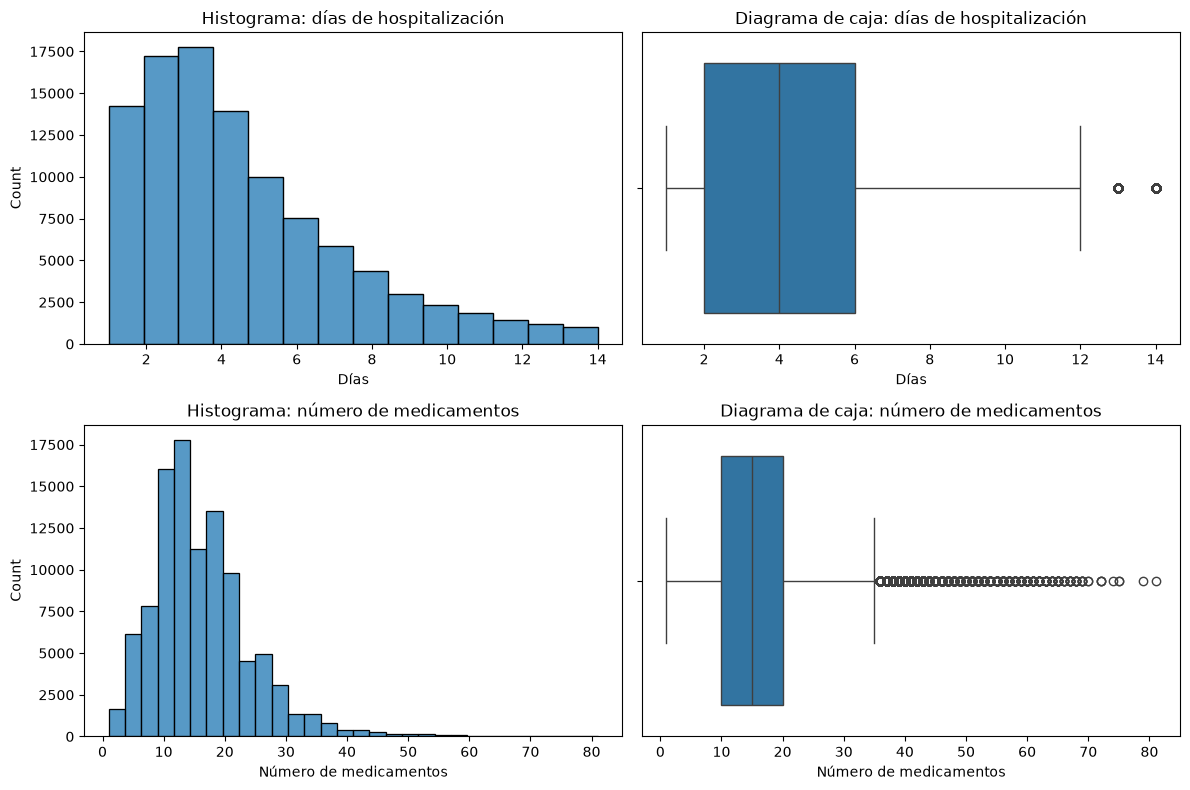

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="time_in_hospital", bins=14, ax=ejes[0, 0])
ejes[0, 0].set_title("Histograma: días de hospitalización")
ejes[0, 0].set_xlabel("Días")

sns.boxplot(data=df, x="time_in_hospital", ax=ejes[0, 1])
ejes[0, 1].set_title("Diagrama de caja: días de hospitalización")
ejes[0, 1].set_xlabel("Días")

sns.histplot(data=df, x="num_medications", bins=30, ax=ejes[1, 0])
ejes[1, 0].set_title("Histograma: número de medicamentos")
ejes[1, 0].set_xlabel("Número de medicamentos")

sns.boxplot(data=df, x="num_medications", ax=ejes[1, 1])
ejes[1, 1].set_title("Diagrama de caja: número de medicamentos")
ejes[1, 1].set_xlabel("Número de medicamentos")

plt.tight_layout()
plt.show()

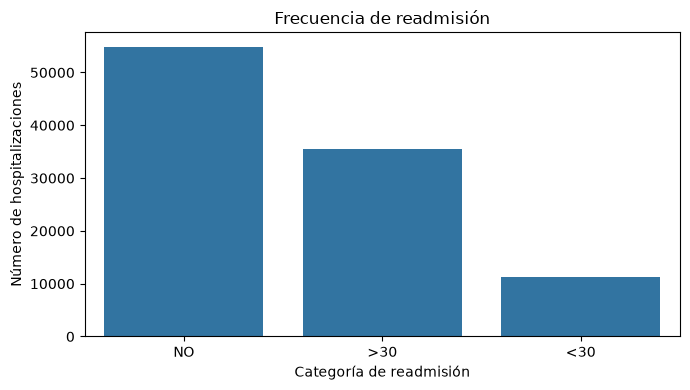

In [13]:
orden = ["NO", ">30", "<30"]

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="readmitted", order=orden)
plt.title("Frecuencia de readmisión")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.tight_layout()
plt.show()

### Interpretación de las visualizaciones

1. **Histograma de días de hospitalización:** las estancias de pocos días son las más frecuentes. La frecuencia disminuye conforme aumenta la duración.
2. **Diagrama de caja de días de hospitalización:** la mitad central de los registros se encuentra entre 2 y 6 días, con una mediana de 4. Se observan valores señalados como atípicos en 13 y 14 días.
3. **Histograma del número de medicamentos:** los registros se concentran principalmente alrededor de 10 a 20 medicamentos. La distribución se extiende hacia valores altos.
4. **Diagrama de caja del número de medicamentos:** la mitad central está entre 10 y 20, con una mediana de 15. Aparecen numerosos valores altos señalados como atípicos.
5. **Gráfico de readmisión:** `NO` es la categoría más frecuente, seguida de `>30` y `<30`, en concordancia con la tabla de frecuencias.

Un valor señalado en un diagrama de caja requiere revisión; el gráfico por sí solo no demuestra que el registro sea incorrecto.

In [14]:
# Detectar valores atípicos mediante IQR en las dos variables graficadas.
resultados_iqr = []

for columna in ["time_in_hospital", "num_medications"]:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = (
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    )

    resultados_iqr.append({
        "variable": columna,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "límite_inferior": limite_inferior,
        "límite_superior": limite_superior,
        "cantidad_atípicos": atipicos.sum(),
        "porcentaje_atípicos": atipicos.mean() * 100
    })

tabla_iqr = pd.DataFrame(resultados_iqr)
display(tabla_iqr.round(2))

,variable,Q1,Q3,IQR,límite_inferior,límite_superior,cantidad_atípicos,porcentaje_atípicos
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.21
1,num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.51


### Detección y decisión sobre valores atípicos

Para `time_in_hospital`, Q1 = 2 y Q3 = 6; el límite superior calculado con IQR es 12. Se detectaron 2 252 valores atípicos (2,21 %).

Para `num_medications`, Q1 = 10 y Q3 = 20; el límite superior es 35. Se detectaron 2 557 valores atípicos (2,51 %).

Se conservarán estos registros porque superar el límite IQR no demuestra que sean errores. Esta decisión evita eliminar hospitalizaciones únicamente por un criterio estadístico. Los valores extremos pueden influir en los resultados del escalamiento, especialmente en Min-Max.

In [15]:
# Conservar df sin modificar y crear una copia de trabajo.
df_limpio = df.copy()

print("Dimensiones antes:", df.shape)
print("Nulos antes en max_glu_serum:", df["max_glu_serum"].isna().sum())
print("Nulos antes en A1Cresult:", df["A1Cresult"].isna().sum())

# En el diccionario de UCI, None significa que la prueba no se realizó.
df_limpio["max_glu_serum"] = df_limpio["max_glu_serum"].fillna("None")
df_limpio["A1Cresult"] = df_limpio["A1Cresult"].fillna("None")

print("Dimensiones después:", df_limpio.shape)
print("Nulos después en max_glu_serum:", df_limpio["max_glu_serum"].isna().sum())
print("Nulos después en A1Cresult:", df_limpio["A1Cresult"].isna().sum())
print("Filas completamente duplicadas:", df_limpio.duplicated().sum())

print("\nNulos en las siete variables cuantitativas:")
display(df_limpio[variables_cuantitativas].isna().sum())

print("Valores negativos en las siete variables cuantitativas:")
display(df_limpio[variables_cuantitativas].lt(0).sum())

Dimensiones antes: (101766, 50)
Nulos antes en max_glu_serum: 96420
Nulos antes en A1Cresult: 84748
Dimensiones después: (101766, 50)
Nulos después en max_glu_serum: 0
Nulos después en A1Cresult: 0
Filas completamente duplicadas: 0

Nulos en las siete variables cuantitativas:


time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64

Valores negativos en las siete variables cuantitativas:


time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64

### Registro de limpieza y selección

Se creó `df_limpio` como copia de trabajo, conservando `df` sin modificar. La tabla mantuvo 101 766 filas y 50 columnas. En `max_glu_serum` y `A1Cresult` se restauró la categoría `None`, que indica que la prueba no se realizó.

No se eliminaron filas: no hay filas completamente duplicadas y las hospitalizaciones repetidas de un paciente pueden ser válidas. Los valores ausentes de otras columnas se conservan, ya que esas columnas no forman parte de las siete variables cuantitativas seleccionadas para el escalamiento.

Las siete variables seleccionadas son de tipo entero y no presentan nulos ni valores negativos. Por tanto, no se requiere imputarlas. Los identificadores, los códigos categóricos y `age` quedan excluidos del escalamiento.

In [16]:
# Conservar los identificadores únicamente como referencia de las filas.
identificadores = df_limpio[["encounter_id", "patient_nbr"]].copy()

# Seleccionar las siete variables cuantitativas sin modificar sus valores.
datos_numericos_limpios = df_limpio[variables_cuantitativas].copy()

print("Tabla de trabajo:", df_limpio.shape)
print("Variables numéricas seleccionadas:", datos_numericos_limpios.shape)
print("Identificadores de referencia:", identificadores.shape)
display(datos_numericos_limpios.head())

# Comprobar que se conservó una fila por cada hospitalización.
assert len(datos_numericos_limpios) == len(df_limpio)
assert datos_numericos_limpios.index.equals(identificadores.index)
assert datos_numericos_limpios.isna().sum().sum() == 0

Tabla de trabajo: (101766, 50)
Variables numéricas seleccionadas: (101766, 7)
Identificadores de referencia: (101766, 2)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


### Normalización Min-Max

Se aplica `MinMaxScaler` a una copia de las siete variables cuantitativas limpias, con rango [0, 1]. Para una variable no constante, la transformación es:

x_normalizado = (x − mínimo) / (máximo − mínimo)

Cada variable se transforma por separado. Los valores extremos determinan sus límites y pueden comprimir los demás valores en una parte pequeña del rango. Si una columna es constante, la fórmula manual tendría denominador cero; `MinMaxScaler` gestiona ese caso. La copia numérica original permanece disponible para realizar después la estandarización de forma independiente.

In [17]:
from sklearn.preprocessing import MinMaxScaler

# Ajustar Min-Max sobre una copia de las siete variables limpias.
escalador_minmax = MinMaxScaler(feature_range=(0, 1))

datos_normalizados = pd.DataFrame(
    escalador_minmax.fit_transform(datos_numericos_limpios.copy()),
    columns=datos_numericos_limpios.columns,
    index=datos_numericos_limpios.index
)

print("Primeras diez filas normalizadas:")
display(datos_normalizados.head(10).round(4))

# Comparar el rango de cada variable antes y después.
tabla_minmax = pd.DataFrame({
    "mínimo_original": datos_numericos_limpios.min(),
    "máximo_original": datos_numericos_limpios.max(),
    "mínimo_normalizado": datos_normalizados.min(),
    "máximo_normalizado": datos_normalizados.max()
})

print("Mínimos y máximos antes y después:")
display(tabla_minmax.round(4))

# Comprobar el rango con una tolerancia numérica.
tolerancia = 1e-9
assert datos_normalizados.index.equals(datos_numericos_limpios.index)
assert (datos_normalizados.min() >= -tolerancia).all()
assert (datos_normalizados.max() <= 1 + tolerancia).all()
print("Comprobación: todos los valores están en el rango [0, 1].")

Primeras diez filas normalizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.0000,0.3053,0.0000,0.0000,0.0000,0.0,0.0000
1,0.1538,0.4427,0.0000,0.2125,0.0000,0.0,0.0000
2,0.0769,0.0763,0.8333,0.1500,0.0476,0.0,0.0476
3,0.0769,0.3282,0.1667,0.1875,0.0000,0.0,0.0000
4,0.0000,0.3817,0.0000,0.0875,0.0000,0.0,0.0000
5,0.1538,0.2290,1.0000,0.1875,0.0000,0.0,0.0000
6,0.2308,0.5267,0.1667,0.2500,0.0000,0.0,0.0000
7,0.3077,0.5496,0.0000,0.1375,0.0000,0.0,0.0000
8,0.9231,0.5115,0.3333,0.3375,0.0000,0.0,0.0000
9,0.8462,0.2443,0.5000,0.2125,0.0000,0.0,0.0000


Mínimos y máximos antes y después:


,mínimo_original,máximo_original,mínimo_normalizado,máximo_normalizado
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Comprobación: todos los valores están en el rango [0, 1].


### Estandarización Z-score

Se aplica `StandardScaler` a otra copia de las siete variables cuantitativas limpias. Para cada variable no constante se calcula:

z = (x − media) / desviación estándar

El resultado debe tener una media aproximadamente igual a 0 y una desviación estándar aproximadamente igual a 1. Para comprobarlo se utiliza `ddof=0`, el mismo criterio de desviación empleado por `StandardScaler`.

Pueden aparecer valores negativos cuando el valor original está por debajo de la media, y valores mayores que 1 cuando se encuentra suficientemente por encima de ella. Si una columna fuera constante, sus valores transformados serían 0 y su desviación resultante sería 0.

In [18]:
from sklearn.preprocessing import StandardScaler

# Ajustar Z-score sobre los datos limpios originales, no sobre Min-Max.
escalador_zscore = StandardScaler()

datos_estandarizados = pd.DataFrame(
    escalador_zscore.fit_transform(datos_numericos_limpios.copy()),
    columns=datos_numericos_limpios.columns,
    index=datos_numericos_limpios.index
)

print("Primeras diez filas estandarizadas:")
display(datos_estandarizados.head(10).round(4))

# Usar ddof=0 para concordar con StandardScaler.
medias_zscore = datos_estandarizados.mean()
desviaciones_zscore = datos_estandarizados.std(ddof=0)

tabla_zscore = pd.DataFrame({
    "media_estandarizada": medias_zscore,
    "desviación_estandarizada": desviaciones_zscore
})

print("Media y desviación estándar por variable:")
display(tabla_zscore.round(4))

# Comprobaciones con tolerancia numérica.
tolerancia = 1e-9
columnas_no_constantes = datos_numericos_limpios.nunique() > 1

assert datos_estandarizados.index.equals(datos_numericos_limpios.index)
assert (medias_zscore.abs() < tolerancia).all()
assert ((desviaciones_zscore[columnas_no_constantes] - 1).abs() < tolerancia).all()
assert (desviaciones_zscore[~columnas_no_constantes].abs() < tolerancia).all()

print("Comprobación: medias cercanas a 0 y desviaciones correctas.")

Primeras diez filas estandarizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.1376,-0.1065,-0.7854,-1.8483,-0.2915,-0.2126,-0.5033
1,-0.4677,0.8084,-0.7854,0.2434,-0.2915,-0.2126,-0.5033
2,-0.8027,-1.6314,2.1458,-0.3718,1.2867,-0.2126,0.2886
3,-0.8027,0.0460,-0.1992,-0.0027,-0.2915,-0.2126,-0.5033
4,-1.1376,0.4018,-0.7854,-0.9870,-0.2915,-0.2126,-0.5033
5,-0.4677,-0.6148,2.7320,-0.0027,-0.2915,-0.2126,-0.5033
6,-0.1327,1.3675,-0.1992,0.6125,-0.2915,-0.2126,-0.5033
7,0.2023,1.5200,-0.7854,-0.4948,-0.2915,-0.2126,-0.5033
8,2.8823,1.2658,0.3871,1.4738,-0.2915,-0.2126,-0.5033
9,2.5473,-0.5131,0.9733,0.2434,-0.2915,-0.2126,-0.5033


Media y desviación estándar por variable:


,media_estandarizada,desviación_estandarizada
time_in_hospital,0.0,1.0
num_lab_procedures,0.0,1.0
num_procedures,-0.0,1.0
num_medications,-0.0,1.0
number_outpatient,0.0,1.0
number_emergency,0.0,1.0
number_inpatient,-0.0,1.0


Comprobación: medias cercanas a 0 y desviaciones correctas.


### Verificación de la estandarización

Las siete variables estandarizadas presentan medias aproximadamente iguales a 0 y desviaciones estándar iguales a 1, calculadas con `ddof=0`. Se observan valores negativos para registros por debajo de la media y valores mayores que 1 para registros alejados por encima de ella. La comprobación del código se completó correctamente.

In [19]:
# Comparar las siete variables en sus tres versiones.
tablas_comparacion = []

for version, datos in [
    ("Original limpio", datos_numericos_limpios),
    ("Normalizado Min-Max", datos_normalizados),
    ("Estandarizado Z-score", datos_estandarizados)
]:
    tabla = pd.DataFrame({
        "variable": datos.columns,
        "versión": version,
        "mínimo": datos.min().values,
        "máximo": datos.max().values,
        "media": datos.mean().values,
        "desviación_estándar": datos.std(ddof=0).values
    })
    tablas_comparacion.append(tabla)

comparacion_estadistica = pd.concat(
    tablas_comparacion, ignore_index=True
)

display(comparacion_estadistica.round(4))

,variable,versión,mínimo,máximo,media,desviación_estándar
0,time_in_hospital,Original limpio,1.0000,14.0000,4.3960,2.9851
1,num_lab_procedures,Original limpio,1.0000,132.0000,43.0956,19.6743
2,num_procedures,Original limpio,0.0000,6.0000,1.3397,1.7058
3,num_medications,Original limpio,1.0000,81.0000,16.0218,8.1275
4,number_outpatient,Original limpio,0.0000,42.0000,0.3694,1.2673
5,number_emergency,Original limpio,0.0000,76.0000,0.1978,0.9305
6,number_inpatient,Original limpio,0.0000,21.0000,0.6356,1.2629
7,time_in_hospital,Normalizado Min-Max,0.0000,1.0000,0.2612,0.2296
8,num_lab_procedures,Normalizado Min-Max,0.0000,1.0000,0.3213,0.1502
9,num_procedures,Normalizado Min-Max,0.0000,1.0000,0.2233,0.2843


### Comparación estadística de las tres versiones

Las siete variables originales conservan sus unidades y rangos distintos. Con Min-Max, cada una queda entre 0 y 1, aunque sus medias y desviaciones no son iguales. Con Z-score, cada variable queda centrada aproximadamente en 0 y tiene desviación estándar igual a 1; sus mínimos y máximos pueden quedar fuera del intervalo [0, 1].

En `number_emergency`, la media normalizada es 0,0026 y el máximo estandarizado es 81,4667. Esto muestra la influencia de un valor máximo muy alejado de la mayor parte de los registros. Cambiar la escala no elimina ese valor.

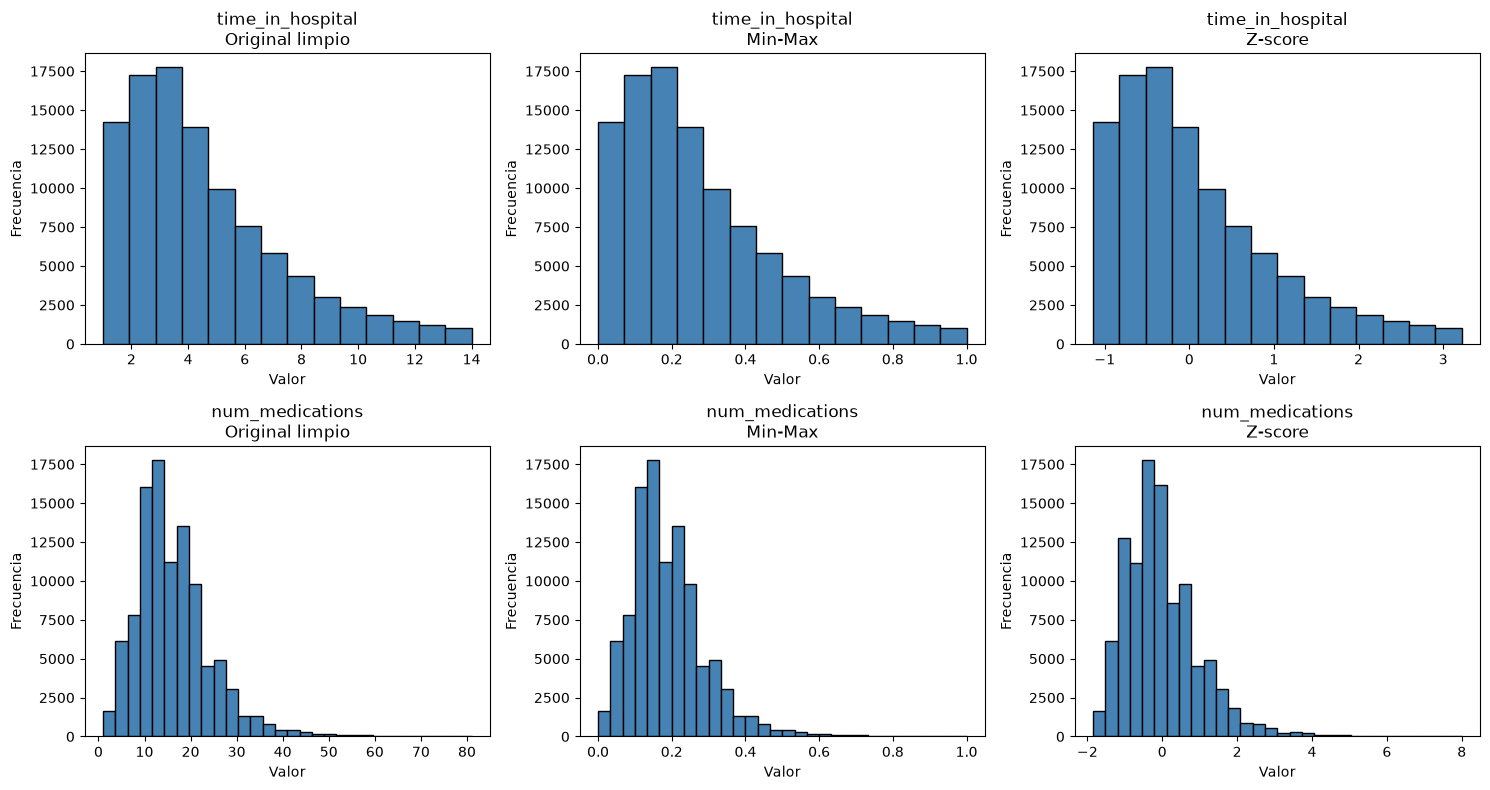

In [20]:
# Comparar las distribuciones antes y después de cada transformación.
versiones = [
    ("Original limpio", datos_numericos_limpios),
    ("Min-Max", datos_normalizados),
    ("Z-score", datos_estandarizados)
]

variables_graficos = [
    ("time_in_hospital", 14),
    ("num_medications", 30)
]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))

for fila, (variable, numero_barras) in enumerate(variables_graficos):
    for columna, (nombre_version, datos) in enumerate(versiones):
        ejes[fila, columna].hist(
            datos[variable],
            bins=numero_barras,
            color="steelblue",
            edgecolor="black"
        )
        ejes[fila, columna].set_title(f"{variable}\n{nombre_version}")
        ejes[fila, columna].set_xlabel("Valor")
        ejes[fila, columna].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### Comparación visual de las transformaciones

En `time_in_hospital`, las tres versiones concentran más hospitalizaciones en los valores bajos y muestran una frecuencia decreciente hacia los valores altos.

En `num_medications`, las tres versiones concentran más registros aproximadamente en el tramo central y mantienen una cola hacia valores altos.

Min-Max y Z-score cambiaron la escala del eje horizontal, pero conservaron el orden de los registros y la forma de ambas distribuciones. Por tanto, cambiar de escala no corrige una distribución asimétrica ni elimina valores extremos.

In [21]:
# Parámetros de time_in_hospital en los datos limpios.
variable = "time_in_hospital"
valores = [1, 2, 3, 4, 5]

minimo = datos_numericos_limpios[variable].min()
maximo = datos_numericos_limpios[variable].max()
media = datos_numericos_limpios[variable].mean()
desviacion = datos_numericos_limpios[variable].std(ddof=0)

print(f"Mínimo: {minimo}")
print(f"Máximo: {maximo}")
print(f"Media: {media:.10f}")
print(f"Desviación estándar (ddof=0): {desviacion:.10f}")

# Buscar un registro real para cada uno de los cinco valores.
indices = [
    datos_numericos_limpios.index[
        datos_numericos_limpios[variable] == valor
    ][0]
    for valor in valores
]

# Aplicar directamente las dos fórmulas y comparar con scikit-learn.
tabla_calculo_manual = pd.DataFrame({
    "registro": indices,
    "valor_original": valores,
    "Min-Max_fórmula": [
        (valor - minimo) / (maximo - minimo)
        for valor in valores
    ],
    "Min-Max_Python": datos_normalizados.loc[indices, variable].to_numpy(),
    "Z-score_fórmula": [
        (valor - media) / desviacion
        for valor in valores
    ],
    "Z-score_Python": datos_estandarizados.loc[indices, variable].to_numpy()
})

display(tabla_calculo_manual.round(4))

Mínimo: 1
Máximo: 14
Media: 4.3959868718
Desviación estándar (ddof=0): 2.9850931009


,registro,valor_original,Min-Max_fórmula,Min-Max_Python,Z-score_fórmula,Z-score_Python
0,0,1,0.0000,0.0000,-1.1376,-1.1376
1,2,2,0.0769,0.0769,-0.8027,-0.8027
2,1,3,0.1538,0.1538,-0.4677,-0.4677
3,6,4,0.2308,0.2308,-0.1327,-0.1327
4,7,5,0.3077,0.3077,0.2023,0.2023


### Comprobación manual de cinco valores

Se eligieron cinco valores reales de `time_in_hospital`: 1, 2, 3, 4 y 5 días.

Parámetros: mínimo = 1, máximo = 14, media = 4,3959868718 y desviación estándar (`ddof=0`) = 2,9850931009.

| Días | Cálculo Min-Max | Resultado | Cálculo Z-score | Resultado |
|---:|---|---:|---|---:|
| 1 | (1 − 1) / (14 − 1) | 0,0000 | (1 − 4,3959868718) / 2,9850931009 | −1,1376 |
| 2 | (2 − 1) / (14 − 1) | 0,0769 | (2 − 4,3959868718) / 2,9850931009 | −0,8027 |
| 3 | (3 − 1) / (14 − 1) | 0,1538 | (3 − 4,3959868718) / 2,9850931009 | −0,4677 |
| 4 | (4 − 1) / (14 − 1) | 0,2308 | (4 − 4,3959868718) / 2,9850931009 | −0,1327 |
| 5 | (5 − 1) / (14 − 1) | 0,3077 | (5 − 4,3959868718) / 2,9850931009 | 0,2023 |

Los diez resultados, redondeados a cuatro decimales, coinciden con los obtenidos mediante `MinMaxScaler` y `StandardScaler`.

In [22]:
# Exportar las siete variables y conservar el índice original como referencia.
datos_normalizados.to_csv(
    "datos_normalizados.csv",
    index=True,
    index_label="indice_original"
)

datos_estandarizados.to_csv(
    "datos_estandarizados.csv",
    index=True,
    index_label="indice_original"
)

# Leer los archivos para comprobar filas, columnas y correspondencia.
normalizados_csv = pd.read_csv(
    "datos_normalizados.csv", index_col="indice_original"
)
estandarizados_csv = pd.read_csv(
    "datos_estandarizados.csv", index_col="indice_original"
)

print("Archivo normalizado:", normalizados_csv.shape)
print("Archivo estandarizado:", estandarizados_csv.shape)

assert normalizados_csv.shape == (len(df), 7)
assert estandarizados_csv.shape == (len(df), 7)
assert list(normalizados_csv.columns) == variables_cuantitativas
assert list(estandarizados_csv.columns) == variables_cuantitativas
assert normalizados_csv.index.equals(estandarizados_csv.index)
assert normalizados_csv.index.equals(identificadores.index)

print("Comprobación: ambos archivos conservan las siete variables")
print("y el mismo índice de los registros originales.")

Archivo normalizado: (101766, 7)
Archivo estandarizado: (101766, 7)
Comprobación: ambos archivos conservan las siete variables
y el mismo índice de los registros originales.


### Exportación y correspondencia de registros

Se generaron `datos_normalizados.csv` y `datos_estandarizados.csv`. Al volver a leerlos, ambos contienen 101 766 filas y las mismas siete variables cuantitativas. La columna `indice_original` conserva la correspondencia entre cada fila transformada y su hospitalización en el conjunto original. No se eliminaron ni inventaron registros.

### Conclusiones

Se analizaron 101 766 hospitalizaciones correspondientes a 71 518 pacientes únicos. La categoría de readmisión más frecuente fue `NO` (53,91 %), seguida de `>30` (34,93 %) y `<30` (11,16 %). Estos resultados describen hospitalizaciones y no permiten establecer causas de readmisión.

Las siete variables cuantitativas seleccionadas no tenían valores ausentes. Se conservaron los registros señalados por IQR porque un valor extremo no demuestra por sí solo un error. La limpieza mantuvo las 101 766 filas.

Min-Max resulta útil cuando se necesita expresar las variables en el intervalo [0, 1]. Z-score permite compararlas respecto de su media y desviación estándar. Ambas transformaciones conservaron la forma de las distribuciones y pueden verse afectadas por valores extremos; ninguna corrigió la asimetría.

El análisis se limita a hospitalizaciones registradas entre 1999 y 2008 en los centros incluidos en el conjunto. Un mismo paciente puede aparecer varias veces. Esta práctica es descriptiva: no se entrenó un modelo ni se realizaron inferencias clínicas o causales.

### Preguntas de reflexión

1. **¿Por qué no escalar un código categórico numérico?** Porque sus números identifican categorías; sus distancias no representan una medición.
2. **¿Cómo afecta un valor extremo?** En Min-Max puede comprimir la mayoría de los valores cerca de un extremo del intervalo. En Z-score influye en la media y la desviación estándar y puede producir puntuaciones muy alejadas de cero.
3. **¿Por qué un paciente repetido no es necesariamente un duplicado?** Porque puede haber tenido varias hospitalizaciones válidas, cada una con su propio `encounter_id`.
4. **¿Escalar corrige la asimetría?** No. Min-Max y Z-score cambian la escala, pero conservan la forma de la distribución.
5. **¿Cómo evitar una futura fuga de información?** Antes de entrenar, se separarían los datos, se ajustarían los escaladores únicamente con entrenamiento y se transformarían los demás conjuntos con esos parámetros. También se evitaría compartir pacientes entre particiones.

**Fuente:** Clore, J., Cios, K., DeShazo, J. y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008*. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

**Asistencia externa:** Se utilizó ChatGPT como apoyo para estructurar el código y la redacción. Los resultados y comprobaciones se ejecutaron en Python sobre el conjunto de datos.

In [23]:
# Comparar descriptivamente dos características según la readmisión.
resumen_por_readmision = df_limpio.groupby("readmitted")[
    ["time_in_hospital", "num_medications"]
].agg(["mean", "median"]).round(2)

display(resumen_por_readmision)

time_in_hospital        num_medications       
                       mean median            mean median
readmitted                                               
<30                    4.77    4.0           16.90   16.0
>30                    4.50    4.0           16.28   15.0
NO                     4.25    3.0           15.67   14.0

### Características según la readmisión

Las hospitalizaciones de la categoría `<30` presentan una duración media de 4,77 días y una media de 16,90 medicamentos. En `>30`, las medias son 4,50 días y 16,28 medicamentos; en `NO`, son 4,25 días y 15,67 medicamentos.

Las medianas también muestran diferencias: en `<30` son 4 días y 16 medicamentos, mientras que en `NO` son 3 días y 14 medicamentos. Estas son comparaciones descriptivas entre hospitalizaciones; no demuestran que la duración o el número de medicamentos causen una readmisión.